# Step 03 — Data preparation for YOLO training
## Подготовка данных для обучения модели YOLO

Picks up where `03_step_Data_preparation_for_Yolo_model_2025.ipynb` stops and produces a dataset that `ultralytics` can train on directly.

What this notebook does:

1. Unpacks `Images.zip` / `labels.zip` and flattens any nested folders.
2. **Really converts** images to JPEG (step 03 only renamed the extension — a PNG called `.jpg` is still a PNG).
3. Audits image/label pairing: orphan images, orphan labels, empty label files.
4. Validates every annotation line against the YOLO format (class id in range, coordinates normalised to [0, 1], non-degenerate boxes).
5. Splits into train/val/test **with real stratification** (step 03 passed `stratify=None`, so the comment about preserved class balance was not in effect).
6. Reports class distribution per split.
7. Writes `data.yaml` — the file YOLO actually needs and which does not exist yet.
8. Archives the result and copies it to Google Drive.

## 0. Setup

In [1]:
import os
import shutil
import zipfile
import random
from pathlib import Path
from collections import defaultdict, Counter

import matplotlib.pyplot as plt
from PIL import Image

from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# ----- CONFIG: the only cell you normally edit -----

DRIVE_DIR  = Path('/content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection')
IMAGES_ZIP = DRIVE_DIR / '/content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/images.zip'
LABELS_ZIP = DRIVE_DIR / '/content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/labels.zip'

RAW_IMAGES  = Path('/content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/raw/images')
RAW_LABELS  = Path('/content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/raw/labels')
DATASET_DIR = Path('/content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/dataset')

# Class order defines the class ids. It MUST match the order used in MakeSense AI.
CLASSES = ['Helmet_with_head', 'Helmet_only', 'Head_without_helmet']

TRAIN_RATIO, VAL_RATIO, TEST_RATIO = 0.70, 0.15, 0.15
SEED = 42

IMG_EXT = {'.jpg', '.jpeg', '.png', '.bmp', '.webp', '.tif', '.tiff'}

random.seed(SEED)
assert abs(TRAIN_RATIO + VAL_RATIO + TEST_RATIO - 1.0) < 1e-9, 'Ratios must sum to 1.0'
print('Classes:', {i: c for i, c in enumerate(CLASSES)})

Classes: {0: 'Helmet_with_head', 1: 'Helmet_only', 2: 'Head_without_helmet'}


## 1. Unpack the archives

Extraction is flattened, so it does not matter whether the zip contains `Images/...` or the files at the root.

In [3]:
def unpack(zip_path, dest, keep_ext):
    """Extract zip_path into dest, flattening directories and keeping only keep_ext files."""
    zip_path = Path(zip_path)
    if not zip_path.exists():
        raise FileNotFoundError(zip_path)

    if dest.exists():
        shutil.rmtree(dest)
    dest.mkdir(parents=True, exist_ok=True)

    tmp = dest.parent / (dest.name + '_tmp')
    if tmp.exists():
        shutil.rmtree(tmp)

    with zipfile.ZipFile(zip_path) as z:
        z.extractall(tmp)

    moved, skipped = 0, 0
    for p in sorted(tmp.rglob('*')):
        if not p.is_file():
            continue
        if p.suffix.lower() not in keep_ext:
            skipped += 1
            continue
        target = dest / p.name
        if target.exists():
            print('  duplicate filename, kept first:', p.name)
            continue
        shutil.move(str(p), str(target))
        moved += 1

    shutil.rmtree(tmp)
    print(f'{zip_path.name}: {moved} files -> {dest}  ({skipped} ignored)')
    return moved


unpack(IMAGES_ZIP, RAW_IMAGES, IMG_EXT)
unpack(LABELS_ZIP, RAW_LABELS, {'.txt'})

images.zip: 123 files -> /content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/raw/images  (0 ignored)
labels.zip: 94 files -> /content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/raw/labels  (0 ignored)


94

In [4]:
# MakeSense AI exports a classes.txt alongside the annotations — it is not an annotation file.
for junk in ['classes.txt', 'labels.txt']:
    p = RAW_LABELS / junk
    if p.exists():
        print('Exported class list found:', p.read_text().split())
        p.unlink()
        print('Removed', junk, '— check that its order matches CLASSES above.')

## 2. Convert images to real JPEG

Step 03 did `os.rename(file, stem + '.jpg')`, which changes the name but not the encoding. Here each file is decoded and re-encoded, which also acts as a corruption check: anything that fails to decode is a broken download and is dropped together with its label.

In [5]:
converted, untouched, corrupt, renamed = [], [], [], []

for p in sorted(RAW_IMAGES.iterdir()):
    if not p.is_file() or p.suffix.lower() not in IMG_EXT:
        continue
    try:
        with Image.open(p) as probe:
            probe.verify()                  # structural check
        with Image.open(p) as im:
            fmt = im.format
            rgb = im.convert('RGB')         # drops alpha / palette / CMYK
            stem = p.stem
            target = p.with_name(stem + '.jpg')

            # a.png and a.jpg in the same folder would overwrite each other
            if target.exists() and target.resolve() != p.resolve():
                stem = p.stem + '_' + p.suffix.lstrip('.').lower()
                target = p.with_name(stem + '.jpg')
                old_lbl = RAW_LABELS / (p.stem + '.txt')
                if old_lbl.exists():
                    old_lbl.rename(RAW_LABELS / (stem + '.txt'))
                renamed.append((p.name, target.name))

            rgb.save(target, 'JPEG', quality=95)

        if target.resolve() != p.resolve():
            p.unlink()
            converted.append((p.name, fmt))
        else:
            untouched.append(p.name)
    except Exception as e:
        corrupt.append((p.name, repr(e)))
        p.unlink(missing_ok=True)
        (RAW_LABELS / (p.stem + '.txt')).unlink(missing_ok=True)

print(f'Re-encoded to JPEG : {len(converted)}')
print(f'Already JPEG       : {len(untouched)}')
print(f'Renamed (collision): {len(renamed)}')
print(f'Corrupt, removed   : {len(corrupt)}')
for name, err in corrupt[:10]:
    print('   ', name, '->', err)

Re-encoded to JPEG : 0
Already JPEG       : 123
Renamed (collision): 0
Corrupt, removed   : 0


## 3. Pairing audit

YOLO matches an image to its label by file stem. Anything unpaired is silently ignored during training, which is how datasets quietly shrink.

In [6]:
image_stems = {p.stem for p in RAW_IMAGES.glob('*.jpg')}
label_stems = {p.stem for p in RAW_LABELS.glob('*.txt')}

images_without_labels = sorted(image_stems - label_stems)
labels_without_images = sorted(label_stems - image_stems)
paired = sorted(image_stems & label_stems)

empty_labels = [s for s in paired if not (RAW_LABELS / (s + '.txt')).read_text().strip()]

print(f'Images                : {len(image_stems)}')
print(f'Labels                : {len(label_stems)}')
print(f'Paired                : {len(paired)}')
print(f'Images without labels : {len(images_without_labels)}')
print(f'Labels without images : {len(labels_without_images)}')
print(f'Empty label files     : {len(empty_labels)}  (valid as backgrounds, but keep them under ~10% of the set)')

for name in images_without_labels[:10]:
    print('   unlabelled image:', name)
for name in labels_without_images[:10]:
    print('   orphan label    :', name)

Images                : 123
Labels                : 94
Paired                : 94
Images without labels : 29
Labels without images : 0
Empty label files     : 0  (valid as backgrounds, but keep them under ~10% of the set)
   unlabelled image: helmet_00022
   unlabelled image: helmet_00026
   unlabelled image: helmet_00029
   unlabelled image: helmet_00071
   unlabelled image: helmet_00072
   unlabelled image: helmet_00073
   unlabelled image: helmet_00075
   unlabelled image: helmet_00076
   unlabelled image: helmet_00077
   unlabelled image: helmet_00078


## 4. Validate the annotation format

Each line must be `class_id cx cy w h`, with the four geometry values normalised to the image size. Files with broken lines are reported and excluded, not silently fed to the trainer.

In [7]:
def validate_label(path, n_classes, tol=1e-6):
    """Return a list of human-readable problems. Empty list == file is fine."""
    problems = []
    for i, line in enumerate(path.read_text().splitlines(), start=1):
        line = line.strip()
        if not line:
            continue
        parts = line.split()
        if len(parts) != 5:
            problems.append(f'line {i}: expected 5 values, got {len(parts)}')
            continue
        try:
            cid = int(parts[0])
            cx, cy, w, h = (float(v) for v in parts[1:])
        except ValueError:
            problems.append(f'line {i}: non-numeric value')
            continue
        if not 0 <= cid < n_classes:
            problems.append(f'line {i}: class id {cid} outside 0..{n_classes - 1}')
        for name, v in (('cx', cx), ('cy', cy), ('w', w), ('h', h)):
            if not -tol <= v <= 1 + tol:
                problems.append(f'line {i}: {name}={v} not normalised to [0, 1]')
        if w <= tol or h <= tol:
            problems.append(f'line {i}: degenerate box (w={w}, h={h})')
        if cx - w / 2 < -tol or cx + w / 2 > 1 + tol or cy - h / 2 < -tol or cy + h / 2 > 1 + tol:
            problems.append(f'line {i}: box extends outside the image')
    return problems


valid_stems, invalid = [], {}
for stem in paired:
    issues = validate_label(RAW_LABELS / (stem + '.txt'), len(CLASSES))
    if issues:
        invalid[stem] = issues
    else:
        valid_stems.append(stem)

print(f'Valid samples   : {len(valid_stems)}')
print(f'Invalid samples : {len(invalid)}')
for stem, issues in list(invalid.items())[:10]:
    print(' ', stem)
    for msg in issues[:3]:
        print('     ', msg)

assert valid_stems, 'No valid image/label pairs — check CLASSES order and the MakeSense export format (YOLO, not VOC/COCO).'

Valid samples   : 94
Invalid samples : 0


## 5. Stratified split

Detection images carry several classes at once, so a single class label per image does not exist. The stratum used here is the *set of classes present in the image*. Images whose combination is too rare to appear in every split fall back to a random assignment — which is reported rather than hidden.

In [8]:
def classes_in(stem):
    ids = set()
    for line in (RAW_LABELS / (stem + '.txt')).read_text().splitlines():
        parts = line.split()
        if len(parts) == 5:
            ids.add(int(parts[0]))
    return frozenset(ids)


strata = defaultdict(list)
for stem in valid_stems:
    strata[classes_in(stem)].append(stem)

splits = {'train': [], 'val': [], 'test': []}
leftovers = []

for key, stems in sorted(strata.items(), key=lambda kv: (-len(kv[1]), sorted(kv[0]))):
    stems = sorted(stems)
    random.Random(SEED).shuffle(stems)
    if len(stems) < 3:
        leftovers.extend(stems)          # too rare to stratify
        continue
    n_train = max(1, round(len(stems) * TRAIN_RATIO))
    n_val   = max(1, round(len(stems) * VAL_RATIO))
    n_train = min(n_train, len(stems) - 2)
    n_val   = min(n_val, len(stems) - n_train - 1)
    splits['train'] += stems[:n_train]
    splits['val']   += stems[n_train:n_train + n_val]
    splits['test']  += stems[n_train + n_val:]

# distribute the un-stratifiable remainder round-robin, weighted by the target ratios
random.Random(SEED).shuffle(leftovers)
order = ['train'] * int(TRAIN_RATIO * 20) + ['val'] * int(VAL_RATIO * 20) + ['test'] * int(TEST_RATIO * 20)
for i, stem in enumerate(leftovers):
    splits[order[i % len(order)]].append(stem)

print(f'Strata (distinct class combinations): {len(strata)}')
print(f'Un-stratifiable samples (<3 of their kind): {len(leftovers)}')
for name, stems in splits.items():
    print(f'  {name:5s}: {len(stems)}')

overlap = set(splits['train']) & (set(splits['val']) | set(splits['test']))
assert not overlap, f'Leakage between splits: {sorted(overlap)[:5]}'

Strata (distinct class combinations): 5
Un-stratifiable samples (<3 of their kind): 1
  train: 65
  val  : 15
  test : 14


In [9]:
# Materialise the YOLO directory layout
if DATASET_DIR.exists():
    shutil.rmtree(DATASET_DIR)

copied = Counter()
for split, stems in splits.items():
    (DATASET_DIR / split / 'images').mkdir(parents=True, exist_ok=True)
    (DATASET_DIR / split / 'labels').mkdir(parents=True, exist_ok=True)
    for stem in stems:
        shutil.copy2(RAW_IMAGES / (stem + '.jpg'), DATASET_DIR / split / 'images' / (stem + '.jpg'))
        shutil.copy2(RAW_LABELS / (stem + '.txt'), DATASET_DIR / split / 'labels' / (stem + '.txt'))
        copied[split] += 1

for split in ('train', 'val', 'test'):
    n_img = len(list((DATASET_DIR / split / 'images').glob('*.jpg')))
    n_lbl = len(list((DATASET_DIR / split / 'labels').glob('*.txt')))
    print(f'{split:5s}: {n_img} images / {n_lbl} labels on disk')
    assert n_img == n_lbl == copied[split]

train: 65 images / 65 labels on disk
val  : 15 images / 15 labels on disk
test : 14 images / 14 labels on disk


## 6. Class distribution per split

class                      train     val    test   total   share
----------------------------------------------------------------
Helmet_with_head             277      45      21     343   88.2%
Helmet_only                    6       1       1       8    2.1%
Head_without_helmet           25      10       3      38    9.8%


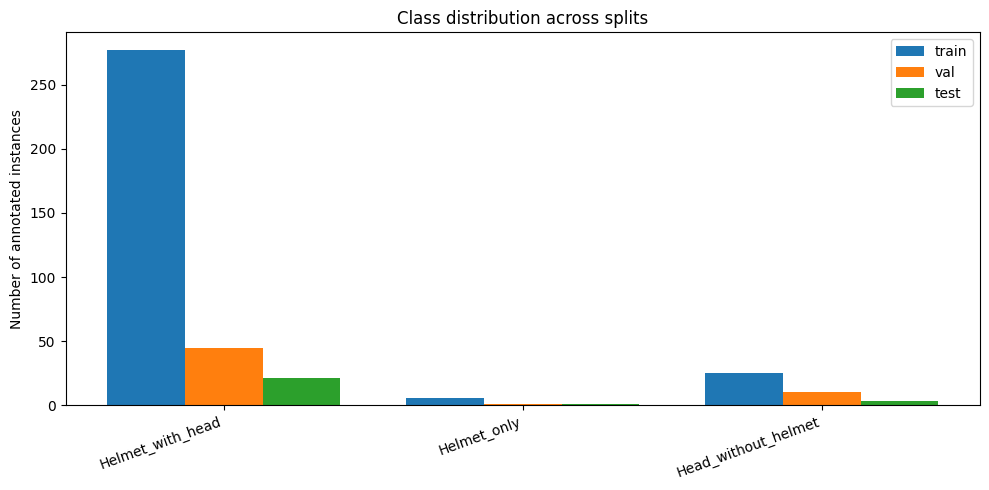


Imbalance ratio Helmet_with_head : Helmet_only = 42.9 : 1
Above ~10:1 the rare class will be under-detected. Collect more of it, or report per-class AP rather than a single mAP in the thesis.


In [10]:
def count_instances(label_dir):
    counts = Counter()
    for txt in Path(label_dir).glob('*.txt'):
        for line in txt.read_text().splitlines():
            parts = line.split()
            if len(parts) == 5:
                counts[CLASSES[int(parts[0])]] += 1
    return counts


per_split = {s: count_instances(DATASET_DIR / s / 'labels') for s in ('train', 'val', 'test')}
total = Counter()
for c in per_split.values():
    total.update(c)

header = f"{'class':24s}" + ''.join(f'{s:>8s}' for s in per_split) + f"{'total':>8s}{'share':>8s}"
print(header)
print('-' * len(header))
grand = sum(total.values()) or 1
for cls in CLASSES:
    row = f'{cls:24s}' + ''.join(f'{per_split[s][cls]:8d}' for s in per_split)
    print(row + f'{total[cls]:8d}{total[cls] / grand:8.1%}')

x = range(len(CLASSES))
width = 0.26
plt.figure(figsize=(10, 5))
for i, split in enumerate(('train', 'val', 'test')):
    plt.bar([v + (i - 1) * width for v in x],
            [per_split[split][c] for c in CLASSES],
            width=width, label=split)
plt.xticks(list(x), CLASSES, rotation=20, ha='right')
plt.ylabel('Number of annotated instances')
plt.title('Class distribution across splits')
plt.legend()
plt.tight_layout()
plt.show()

if grand > 1:
    rarest, most = min(total, key=total.get), max(total, key=total.get)
    ratio = total[most] / max(total[rarest], 1)
    print(f'\nImbalance ratio {most} : {rarest} = {ratio:.1f} : 1')
    if ratio > 10:
        print('Above ~10:1 the rare class will be under-detected. Collect more of it, or '
              'report per-class AP rather than a single mAP in the thesis.')

## 7. Write `data.yaml`

This is the file passed to `model.train(data=...)`. Without it there is nothing to train on.

In [11]:
yaml_text = (

    f'path: {DATASET_DIR}\n'
    'train: train/images\n'
    'val: val/images\n'
    'test: test/images\n'
    '\n'
    f'nc: {len(CLASSES)}\n'
    'names:\n'
    + ''.join(f'  {i}: {c}\n' for i, c in enumerate(CLASSES))
)

yaml_path = DATASET_DIR / 'data.yaml'
yaml_path.write_text(yaml_text)
print(yaml_path)
print(yaml_text)

/content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/dataset/data.yaml
path: /content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/dataset
train: train/images
val: val/images
test: test/images

nc: 3
names:
  0: Helmet_with_head
  1: Helmet_only
  2: Head_without_helmet



## 8. Visual sanity check — draw a few boxes back onto the images

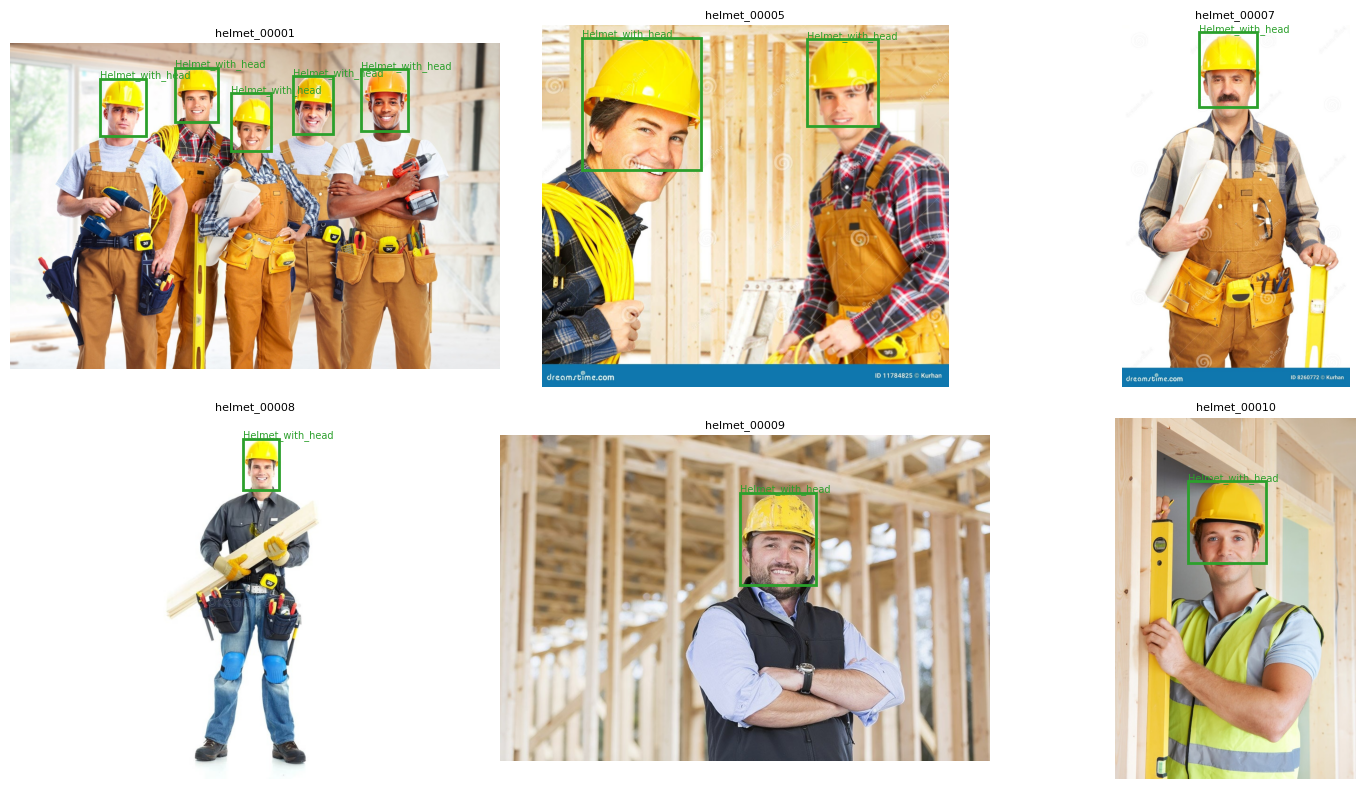

In [12]:
import matplotlib.patches as patches

sample = sorted((DATASET_DIR / 'train' / 'images').glob('*.jpg'))[:6]
colors = ['#2ca02c', '#ff7f0e', '#d62728']

if sample:
    cols = min(3, len(sample))
    rows = (len(sample) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(5 * cols, 4 * rows))
    axes = [axes] if len(sample) == 1 else list(axes.flat)

    for ax, img_path in zip(axes, sample):
        im = Image.open(img_path)
        W, H = im.size
        ax.imshow(im)
        ax.axis('off')
        ax.set_title(img_path.stem[:34], fontsize=8)
        lbl = DATASET_DIR / 'train' / 'labels' / (img_path.stem + '.txt')
        for line in lbl.read_text().splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            cid = int(parts[0])
            cx, cy, w, h = (float(v) for v in parts[1:])
            ax.add_patch(patches.Rectangle(
                ((cx - w / 2) * W, (cy - h / 2) * H), w * W, h * H,
                linewidth=2, edgecolor=colors[cid % len(colors)], facecolor='none'))
            ax.text((cx - w / 2) * W, (cy - h / 2) * H - 4, CLASSES[cid],
                    color=colors[cid % len(colors)], fontsize=7)

    for ax in axes[len(sample):]:
        ax.axis('off')
    plt.tight_layout()
    plt.show()
else:
    print('Training split is empty.')

Boxes must sit on the objects. If they are shifted, mirrored or scaled, the export from MakeSense AI was not in YOLO format — re-export and re-run from step 1.

If a label on a box is the wrong name, `CLASSES` is in a different order than the class list used during annotation. Fix the order in the config cell; do not edit the `.txt` files.

## 9. Archive and copy to Google Drive

In [14]:
archive = shutil.make_archive('/content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/', 'zip', DATASET_DIR)
size_mb = os.path.getsize(archive) / 1024 ** 2
print(f'{archive}  ({size_mb:.1f} MB)')

shutil.copy2(archive, DRIVE_DIR / 'YOLO_dataset_ready.zip')
print('Copied to', DRIVE_DIR / 'YOLO_dataset_ready.zip')

/content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/.zip  (34.1 MB)
Copied to /content/drive/MyDrive/AI-Learning/Project_Development/Data_Collection/YOLO_dataset_ready.zip


## 10. Hand-off to training

The next notebook only needs the two lines below. Run them here as a smoke test on 3 epochs first — if the data is wrong, it fails in two minutes instead of two hours.

In [15]:
 !pip install -q ultralytics

from ultralytics import YOLO
 model = YOLO('yolo11n.pt')
 model.train(data=str(DATASET_DIR / 'data.yaml'), epochs=3, imgsz=640, batch=8, seed=SEED)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.9/46.9 kB 1.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 19.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 58.1/58.1 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.1/96.1 kB 6.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.174 🚀 Python-3.13.16 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=Fa

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x791640d12b10>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.047047,
          0.04